# Proyecto final: valuación del convertible de Coca-Cola (KO)
Derivados y Administración de Riesgos Corporativos · EGADE Business School
Equipo: Carmen Abigail Cázares Báez · Edgar Jiménez · Diana Lozada · Profesor: Dr. Raymundo Díaz Robles

El notebook busca refinanciar 3,000 millones de dólares con un
bono convertible, un call spread y un T-lock. Contenido:

1. Descarga de datos y volatilidad (histórica, EWMA y GARCH(1,1) contra la implícita de Bloomberg)
2. Parámetros de mercado
3. Valuación del convertible: bono recto + call con Black-Scholes y árbol binomial CRR
4. Árbol binomial: convergencia y primeros nodos
5. Cupón justo según prima de conversión y volatilidad
6. Call spread y prima efectiva
7. Griegas de la posición
8. Escenarios: precio y volatilidad
9. Monte Carlo: probabilidad de conversión y costo de la dilución
10. Cobertura de tasa: T-lock con el DV01 de Bloomberg
11. Resultado del portafolio de cobertura en Investopedia
12. Conclusión

Datos de mercado: Bloomberg (OMON, USGG5YR, SWPM) y LSEG (dividendo y CDS) al 9 de noviembre de 2026.

In [1]:
import numpy as np
import pandas as pd
from scipy.stats import norm
from scipy.optimize import brentq, minimize
import matplotlib.pyplot as plt

BERRY = ["#8c1d40", "#c0506f", "#d99aab", "#d9a441", "#8a7a80"]
plt.rcParams.update({"font.family": "serif", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})
pd.options.display.float_format = "{:,.4f}".format

## 1. Descarga de datos y volatilidad
Se descargan cinco años de precios de KO con yfinance. La valuación usa el precio de Bloomberg del 9 de noviembre
(96.03) para que coincida con las volatilidades implícitas de esa fecha; la serie histórica sirve para comparar
la volatilidad histórica, EWMA y GARCH(1,1) contra la implícita.

In [2]:
S0 = 96.03            # precio de KO en Bloomberg, 9-nov-2026 (fecha de valuación)
IV_BBG = 0.2018       # volatilidad implícita IVM, strike 120, ene-2029 (Bloomberg OMON)
try:
    import yfinance as yf
    px = yf.download("KO", start="2021-11-01", end="2026-11-10", auto_adjust=True, progress=False)["Close"].squeeze().dropna()
    if len(px) < 500: raise ValueError("serie incompleta")
    fuente = "Yahoo Finance"
except Exception as e:
    # Respaldo solo para que el notebook corra sin internet; en Colab se usan datos reales.
    rng = np.random.default_rng(7); n = 1260
    px = pd.Series(np.exp(np.cumsum(rng.normal(0, 0.2 / np.sqrt(252), n))), index=pd.bdate_range(end="2026-11-09", periods=n))
    px = px * S0 / px.iloc[-1]
    fuente = f"DATOS SIMULADOS (sin conexión: {type(e).__name__})"
r = np.log(px).diff().dropna()
print(f"Fuente: {fuente} | Observaciones: {len(px)} | Último precio en la serie: {px.iloc[-1]:.2f}")

Fuente: Yahoo Finance | Observaciones: 1261 | Último precio en la serie: 96.03


In [3]:
# Volatilidad histórica móvil de 30 días y EWMA (RiskMetrics, lambda = 0.94)
vol30 = r.rolling(30).std() * np.sqrt(252)
lam = 0.94; ewma_var = np.empty(len(r)); ewma_var[0] = r.var()
for t in range(1, len(r)):
    ewma_var[t] = lam * ewma_var[t - 1] + (1 - lam) * r.iloc[t - 1] ** 2
vol_ewma = pd.Series(np.sqrt(ewma_var * 252), index=r.index)

# GARCH(1,1) estimado por máxima verosimilitud
def garch_nll(params, x):
    w, a, b = params
    if w <= 0 or a < 0 or b < 0 or a + b >= 1: return 1e10
    v = np.empty(len(x)); v[0] = x.var()
    for t in range(1, len(x)): v[t] = w + a * x[t - 1] ** 2 + b * v[t - 1]
    return 0.5 * np.sum(np.log(2 * np.pi * v) + x ** 2 / v)
x = (r - r.mean()).values
res = minimize(garch_nll, x0=[x.var() * 0.05, 0.08, 0.90], args=(x,), method="Nelder-Mead", options={"maxiter": 4000})
w, a, b = res.x
v = np.empty(len(x)); v[0] = x.var()
for t in range(1, len(x)): v[t] = w + a * x[t - 1] ** 2 + b * v[t - 1]
vol_garch = pd.Series(np.sqrt(v * 252), index=r.index)
VL = w / (1 - a - b)                                    # varianza de largo plazo
h = np.arange(1, 252 * 5 + 1)
v_next = w + a * x[-1] ** 2 + b * v[-1]
v_fore = VL + (a + b) ** (h - 1) * (v_next - VL)        # pronóstico de varianza diaria
vol_garch_5a = np.sqrt(v_fore.mean() * 252)

tabla_vol = pd.DataFrame({"Volatilidad anual": [r.std() * np.sqrt(252), vol30.iloc[-1], vol_ewma.iloc[-1],
                                                 np.sqrt(VL * 252), vol_garch_5a, IV_BBG]},
                         index=["Histórica 5 años", "Histórica 30 días", "EWMA (λ = 0.94)", "GARCH largo plazo",
                                "GARCH promedio a 5 años", "Implícita Bloomberg (strike 120, ene-2029)"])
print(f"GARCH(1,1): omega = {w:.2e}, alpha = {a:.4f}, beta = {b:.4f}, persistencia = {a + b:.4f}")
tabla_vol

GARCH(1,1): omega = 4.82e-06, alpha = 0.0669, beta = 0.8930, persistencia = 0.9599


,Volatilidad anual
Histórica 5 años,0.1684
Histórica 30 días,0.1980
EWMA (λ = 0.94),0.1987
GARCH largo plazo,0.1740
GARCH promedio a 5 años,0.1741
"Implícita Bloomberg (strike 120, ene-2029)",0.2018


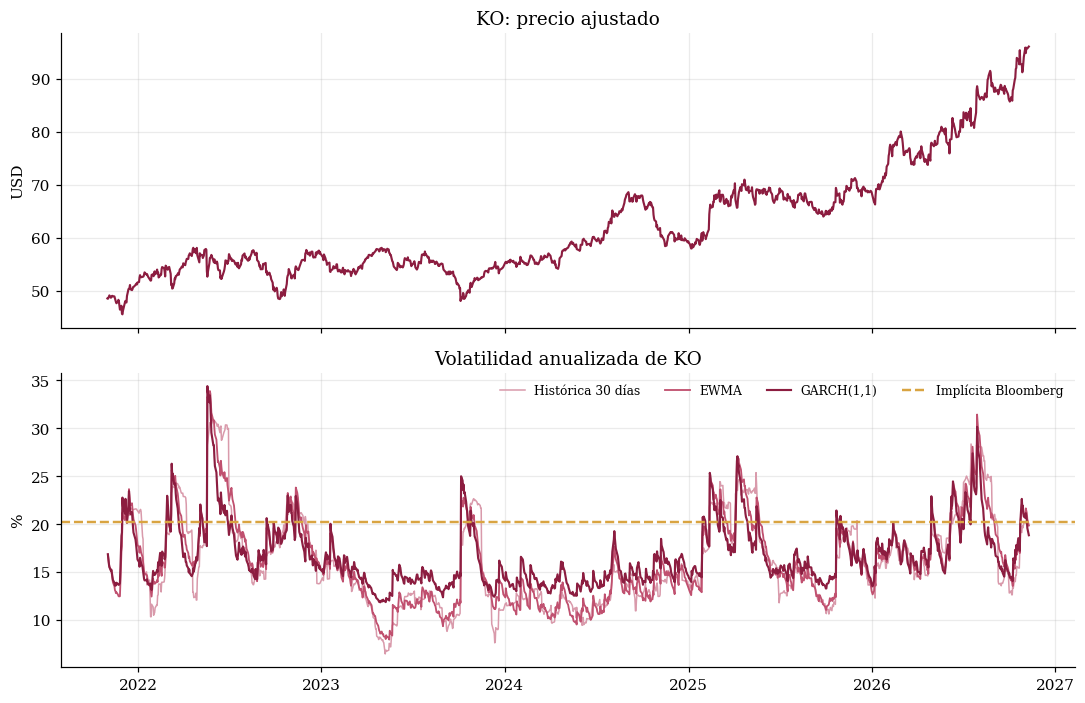

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
ax[0].plot(px.index, px.values, color=BERRY[0], lw=1.4)
ax[0].set(title="KO: precio ajustado", ylabel="USD")
ax[1].plot(vol30.index, vol30 * 100, color=BERRY[2], lw=1, label="Histórica 30 días")
ax[1].plot(vol_ewma.index, vol_ewma * 100, color=BERRY[1], lw=1.2, label="EWMA")
ax[1].plot(vol_garch.index, vol_garch * 100, color=BERRY[0], lw=1.4, label="GARCH(1,1)")
ax[1].axhline(IV_BBG * 100, color=BERRY[3], ls="--", lw=1.6, label="Implícita Bloomberg")
ax[1].set(title="Volatilidad anualizada de KO", ylabel="%"); ax[1].legend(frameon=False, ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

**Lectura.** La volatilidad implícita de Bloomberg es la que usa el mercado para valuar opciones de KO, por eso es
la que entra en la valuación. Los modelos EWMA y GARCH sirven de contraste: si la implícita está por encima del
pronóstico GARCH a 5 años, las opciones se ven "caras" y vender warrants le conviene a Coca-Cola; si está por
debajo, comprar el call spread sale relativamente barato.

## 2. Parámetros de mercado

In [5]:
sigma   = 0.2018    # IVM strike 120 (conversión), Bloomberg OMON ene-2029
sigma_w = 0.1990    # IVM strike ≈ 154 (warrant), Bloomberg OMON ene-2029
q       = 0.0221    # rendimiento por dividendo (LSEG SOV y Bloomberg DES)
rf      = 0.046767  # Tesoro a 5 años, Bloomberg USGG5YR
swap5   = 0.043975  # swap SOFR a 5 años, Bloomberg SWPM
spread  = 0.003456  # CDS a 5 años de KO: 34.6 pb (LSEG CDS Overview)
plazo, nominal = 5, 1000
monto = 3_000e6     # bonos en USD que vencen entre marzo y junio de 2027
prima_conv, prima_techo = 0.25, 0.60
y_recta = rf + spread
pd.DataFrame({"Valor": [S0, sigma, sigma_w, q, rf, swap5, spread, y_recta]},
             index=["Precio de KO", "Vol. implícita strike 120", "Vol. implícita warrant", "Dividendo",
                    "Tesoro 5 años", "Swap SOFR 5 años", "CDS 5 años", "Rendimiento deuda recta"])

,Valor
Precio de KO,96.0300
Vol. implícita strike 120,0.2018
Vol. implícita warrant,0.1990
Dividendo,0.0221
Tesoro 5 años,0.0468
Swap SOFR 5 años,0.0440
CDS 5 años,0.0035
Rendimiento deuda recta,0.0502


## 3. Valuación del convertible: bono recto + call

In [6]:
def bs_call(S, K, T, r, q, s):
    d1 = (np.log(S / K) + (r - q + s**2 / 2) * T) / (s * np.sqrt(T)); d2 = d1 - s * np.sqrt(T)
    return S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

def bs_greeks(S, K, T, r, q, s):
    d1 = (np.log(S / K) + (r - q + s**2 / 2) * T) / (s * np.sqrt(T)); d2 = d1 - s * np.sqrt(T)
    return {"Delta": np.exp(-q * T) * norm.cdf(d1),
            "Gamma": np.exp(-q * T) * norm.pdf(d1) / (S * s * np.sqrt(T)),
            "Vega (por punto)": S * np.exp(-q * T) * norm.pdf(d1) * np.sqrt(T) / 100,
            "Theta (por día)": (-S * np.exp(-q * T) * norm.pdf(d1) * s / (2 * np.sqrt(T))
                                + q * S * np.exp(-q * T) * norm.cdf(d1) - r * K * np.exp(-r * T) * norm.cdf(d2)) / 365}

def crr_call(S, K, T, r, q, s, N=500, americana=True):
    dt = T / N; u = np.exp(s * np.sqrt(dt)); d = 1 / u; p = (np.exp((r - q) * dt) - d) / (u - d)
    j = np.arange(N + 1); V = np.maximum(S * u**j * d**(N - j) - K, 0)
    for i in range(N - 1, -1, -1):
        V = np.exp(-r * dt) * (p * V[1:i + 2] + (1 - p) * V[:i + 1])
        if americana:
            j = np.arange(i + 1); V = np.maximum(V, S * u**j * d**(i - j) - K)
    return V[0]

def bono_recto(cupon, y, T, F=1000):
    t = np.arange(1, T + 1)
    return np.sum(cupon * F / (1 + y)**t) + F / (1 + y)**T

K_conv = S0 * (1 + prima_conv); ratio = nominal / K_conv
call_bs = bs_call(S0, K_conv, plazo, rf, q, sigma)
call_eur = crr_call(S0, K_conv, plazo, rf, q, sigma, americana=False)
call_am = crr_call(S0, K_conv, plazo, rf, q, sigma, americana=True)
valor_opcion = ratio * call_bs
cupon_justo = brentq(lambda c: bono_recto(c, y_recta, plazo) + valor_opcion - nominal, -0.05, 0.2)
ahorro = (y_recta - cupon_justo) * monto

pd.DataFrame({"Valor": [K_conv, ratio, call_bs, call_eur, call_am, valor_opcion, bono_recto(cupon_justo, y_recta, plazo),
                        y_recta, cupon_justo, ahorro / 1e6]},
             index=["Precio de conversión", "Acciones por bono", "Call Black-Scholes", "Call árbol europeo (N=500)",
                    "Call árbol americano (N=500)", "Valor de la opción por bono", "Bono recto al cupón justo",
                    "Rendimiento deuda recta", "Cupón justo", "Ahorro anual (MDD)"])

,Valor
Precio de conversión,120.0375
Acciones por bono,8.3307
Call Black-Scholes,12.0279
Call árbol europeo (N=500),12.0336
Call árbol americano (N=500),12.0458
Valor de la opción por bono,100.2014
Bono recto al cupón justo,899.7986
Rendimiento deuda recta,0.0502
Cupón justo,0.0271
Ahorro anual (MDD),69.4748


## 4. Árbol binomial: convergencia y primeros nodos

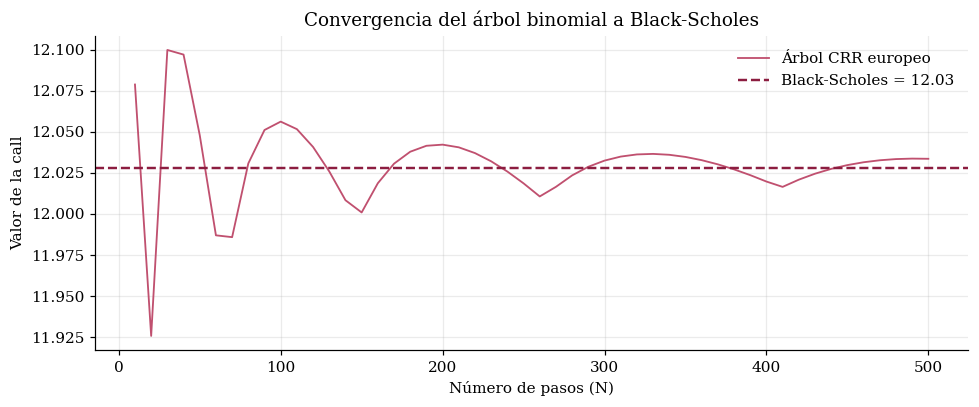

In [7]:
Ns = np.arange(10, 501, 10)
conv = [crr_call(S0, K_conv, plazo, rf, q, sigma, N=n, americana=False) for n in Ns]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(Ns, conv, color=BERRY[1], lw=1.2, label="Árbol CRR europeo")
ax.axhline(call_bs, color=BERRY[0], ls="--", lw=1.6, label=f"Black-Scholes = {call_bs:.2f}")
ax.set(title="Convergencia del árbol binomial a Black-Scholes", xlabel="Número de pasos (N)", ylabel="Valor de la call")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

Nodos con ejercicio anticipado: 0


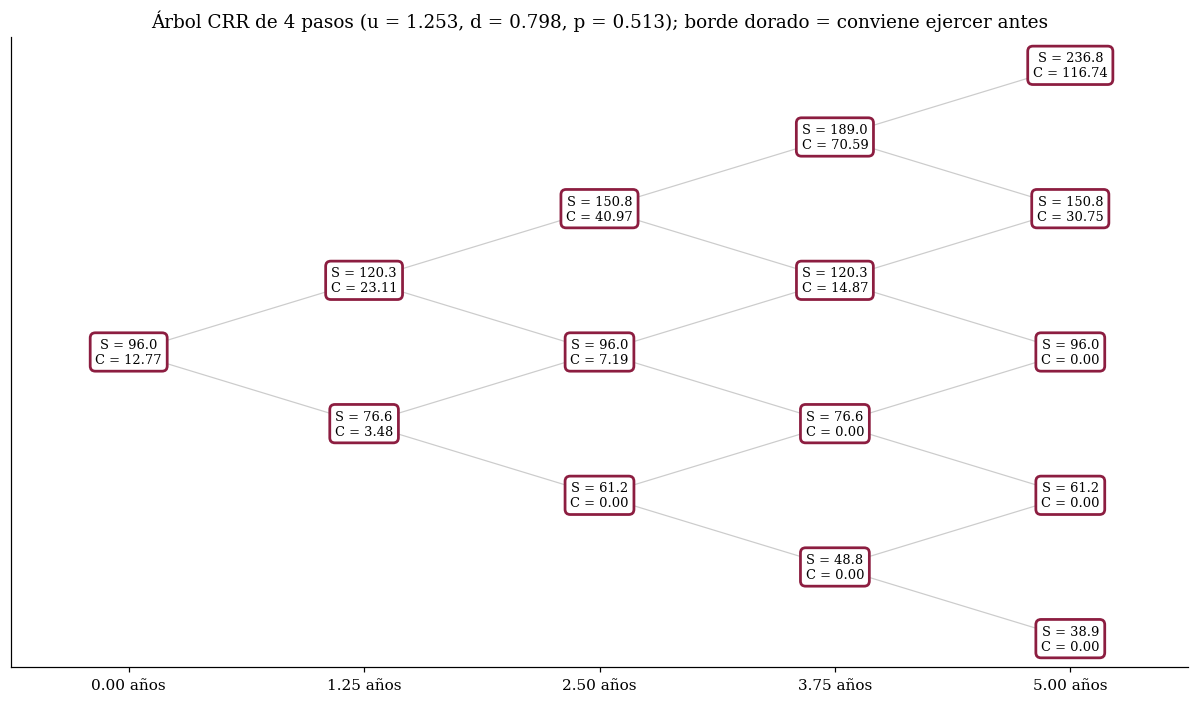

In [8]:
# Árbol de 4 pasos (un paso = 1.25 años): precio de KO y valor de la call americana en cada nodo
N4 = 4; dt = plazo / N4; u = np.exp(sigma * np.sqrt(dt)); d = 1 / u; p = (np.exp((rf - q) * dt) - d) / (u - d)
S_n = [[S0 * u**j * d**(i - j) for j in range(i + 1)] for i in range(N4 + 1)]
V_n = [None] * (N4 + 1); V_n[N4] = [max(s - K_conv, 0) for s in S_n[N4]]; ejer = [[False] * (i + 1) for i in range(N4 + 1)]
for i in range(N4 - 1, -1, -1):
    V_n[i] = []
    for j in range(i + 1):
        cont = np.exp(-rf * dt) * (p * V_n[i + 1][j + 1] + (1 - p) * V_n[i + 1][j]); ej = S_n[i][j] - K_conv
        V_n[i].append(max(cont, ej)); ejer[i][j] = ej > cont
fig, ax = plt.subplots(figsize=(11, 6.5))
for i in range(N4 + 1):
    for j in range(i + 1):
        y = (j - i / 2) * 1.6
        if i < N4:
            for jj in (j, j + 1): ax.plot([i, i + 1], [y, (jj - (i + 1) / 2) * 1.6], color="#cccccc", lw=0.8, zorder=1)
        col = BERRY[3] if ejer[i][j] else BERRY[0]
        ax.text(i, y, f"S = {S_n[i][j]:.1f}\nC = {V_n[i][j]:.2f}", ha="center", va="center", fontsize=8.5, zorder=3,
                bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=col, lw=1.8))
ax.set(title=f"Árbol CRR de 4 pasos (u = {u:.3f}, d = {d:.3f}, p = {p:.3f}); borde dorado = conviene ejercer antes",
       xticks=range(N4 + 1), xticklabels=[f"{i * dt:.2f} años" for i in range(N4 + 1)], yticks=[], xlim=(-0.5, N4 + 0.5))
print("Nodos con ejercicio anticipado:", sum(e for fila in ejer[:-1] for e in fila))
ax.grid(False); plt.tight_layout(); plt.show()

**Lectura.** Con 500 pasos el árbol converge al valor de Black-Scholes. La call americana vale casi lo mismo que la
europea: con un dividendo de 2.2 % y una tasa de 4.7 %, el valor del tiempo casi siempre supera al dividendo que se
deja de cobrar, así que no conviene ejercer antes y Black-Scholes es una buena aproximación para el convertible.

## 5. Cupón justo según prima de conversión y volatilidad

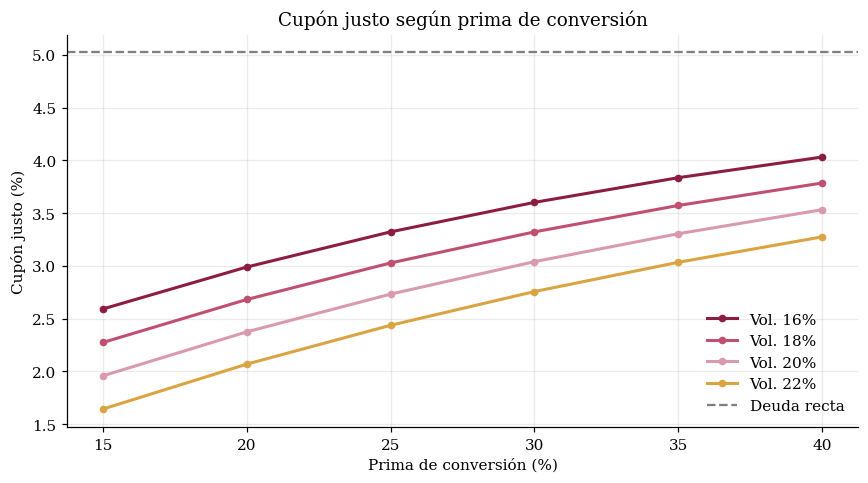

,Vol. 16%,Vol. 18%,Vol. 20%,Vol. 22%
15%,2.5900,2.2800,1.9600,1.6400
20%,2.9900,2.6800,2.3800,2.0700
25%,3.3200,3.0300,2.7300,2.4400
30%,3.6000,3.3200,3.0400,2.7600
35%,3.8400,3.5700,3.3000,3.0300
40%,4.0300,3.7900,3.5300,3.2800


In [9]:
def cupon_para(prima, s):
    K = S0 * (1 + prima); op = (nominal / K) * bs_call(S0, K, plazo, rf, q, s)
    return brentq(lambda c: bono_recto(c, y_recta, plazo) + op - nominal, -0.1, 0.2)
primas = np.arange(0.15, 0.41, 0.05); vols = [0.16, 0.18, 0.20, 0.22]
malla = pd.DataFrame({f"Vol. {v:.0%}": [cupon_para(p_, v) * 100 for p_ in primas] for v in vols},
                     index=[f"{p_:.0%}" for p_ in primas])
fig, ax = plt.subplots(figsize=(8, 4.5))
for (col, serie), c in zip(malla.items(), BERRY): ax.plot(primas * 100, serie, color=c, lw=2, marker="o", ms=4, label=col)
ax.axhline(y_recta * 100, ls="--", color="gray", label="Deuda recta")
ax.set(title="Cupón justo según prima de conversión", xlabel="Prima de conversión (%)", ylabel="Cupón justo (%)")
ax.legend(frameon=False); plt.tight_layout(); plt.show()
malla.round(2)

**No hay almuerzo gratis.** Cada punto más de prima de conversión sube el cupón justo, porque la opción entregada
vale menos. Con 25 % de prima el cupón queda unos 2.3 puntos por debajo de la deuda recta.

## 6. Call spread y prima efectiva

,Valor
Acciones subyacentes (millones),24.9922
Strike calls (note hedge),120.0375
Strike warrants,153.6480
Calls compradas (MDD),300.6043
Warrants vendidos (MDD),139.7793
Costo neto (MDD),160.8250
Costo neto / emisión,0.0536
Años de ahorro para pagarlo,2.3149


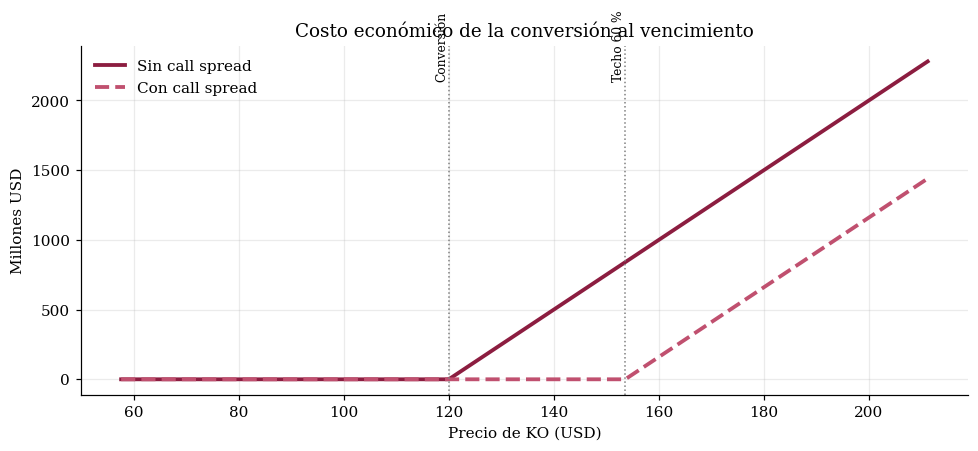

In [10]:
K_techo = S0 * (1 + prima_techo); acciones = ratio * monto / nominal
c_compra, c_venta = bs_call(S0, K_conv, plazo, rf, q, sigma), bs_call(S0, K_techo, plazo, rf, q, sigma_w)
costo_neto = (c_compra - c_venta) * acciones
display(pd.DataFrame({"Valor": [acciones / 1e6, K_conv, K_techo, c_compra * acciones / 1e6, c_venta * acciones / 1e6,
                                costo_neto / 1e6, costo_neto / monto, costo_neto / ahorro]},
             index=["Acciones subyacentes (millones)", "Strike calls (note hedge)", "Strike warrants", "Calls compradas (MDD)",
                    "Warrants vendidos (MDD)", "Costo neto (MDD)", "Costo neto / emisión", "Años de ahorro para pagarlo"]))

ST = np.linspace(0.6, 2.2, 300) * S0
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(ST, np.maximum(ST - K_conv, 0) * acciones / 1e6, color=BERRY[0], lw=2.5, label="Sin call spread")
ax.plot(ST, np.maximum(ST - K_techo, 0) * acciones / 1e6, color=BERRY[1], lw=2.5, ls="--", label="Con call spread")
for k, t in [(K_conv, "Conversión"), (K_techo, "Techo 60 %")]:
    ax.axvline(k, color="gray", ls=":", lw=1); ax.text(k, ax.get_ylim()[1] * 0.9, t, rotation=90, fontsize=8, ha="right")
ax.set(title="Costo económico de la conversión al vencimiento", xlabel="Precio de KO (USD)", ylabel="Millones USD")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 7. Griegas de la posición

,Calls compradas,Warrants vendidos,Call spread neto
Delta,"11,228,391.9800","6,465,059.6200","4,763,332.3600"
Gamma,"206,019.1000","178,941.6300","27,077.4700"
Vega (por punto),"19,169,575.9300","16,419,061.2900","2,750,514.6500"
Theta (por día),"-140,337.9300","-113,564.7300","-26,773.2000"


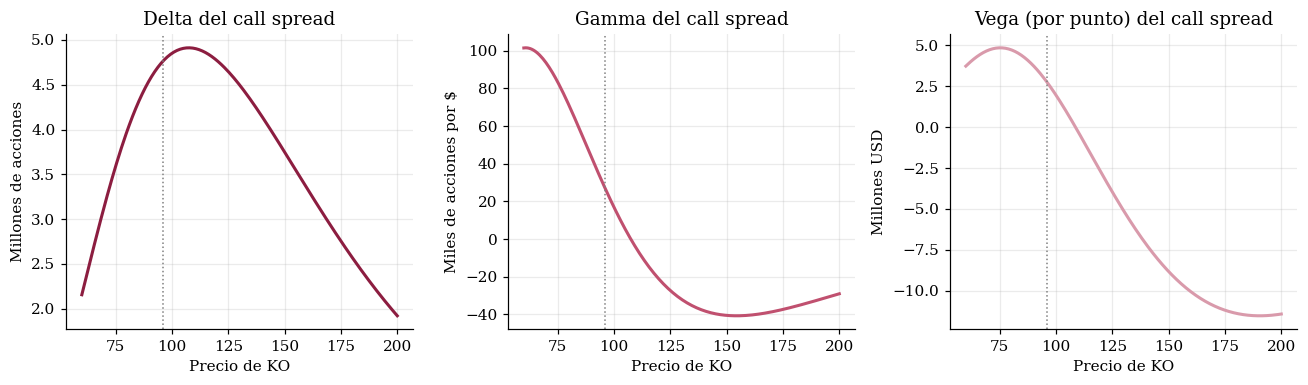

In [11]:
g_c = pd.Series(bs_greeks(S0, K_conv, plazo, rf, q, sigma)) * acciones
g_v = pd.Series(bs_greeks(S0, K_techo, plazo, rf, q, sigma_w)) * acciones
display(pd.DataFrame({"Calls compradas": g_c, "Warrants vendidos": g_v, "Call spread neto": g_c - g_v}).round(2))

Sg = np.linspace(60, 200, 200)
G = {k: np.array([bs_greeks(s, K_conv, plazo, rf, q, sigma)[k] - bs_greeks(s, K_techo, plazo, rf, q, sigma_w)[k] for s in Sg]) * acciones
     for k in ["Delta", "Gamma", "Vega (por punto)"]}
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for a_, (k, val), c, esc_ in zip(ax, G.items(), BERRY, [1e6, 1e3, 1e6]):
    a_.plot(Sg, val / esc_, color=c, lw=2); a_.axvline(S0, color="gray", ls=":", lw=1)
    a_.set(title=f"{k} del call spread", xlabel="Precio de KO", ylabel=["Millones de acciones", "Miles de acciones por $", "Millones USD"][list(G).index(k)])
plt.tight_layout(); plt.show()

**Lectura.** La delta es positiva en todo el rango: el call spread gana cuando KO sube, justo cuando la conversión le
cuesta más a la empresa, y su efecto es mayor cerca del precio de conversión. La gamma y la vega son positivas al
precio actual, pero se vuelven negativas cuando KO se acerca al techo, porque ahí pesa más el warrant vendido: por
encima de 154 dólares el call spread ya pagó casi todo lo que puede pagar.

## 8. Escenarios: precio y volatilidad

,Precio de KO,Valor call spread en 1 año (MDD),Ganancia vs. costo (MDD)
-30%,67.2000,32.9000,-127.9000
-15%,81.6000,80.7000,-80.1000
+0%,96.0000,148.2000,-12.7000
+15%,110.4000,226.4000,65.6000
+30%,124.8000,306.1000,145.2000
+60%,153.6000,445.7000,284.9000
+80%,172.9000,516.5000,355.7000


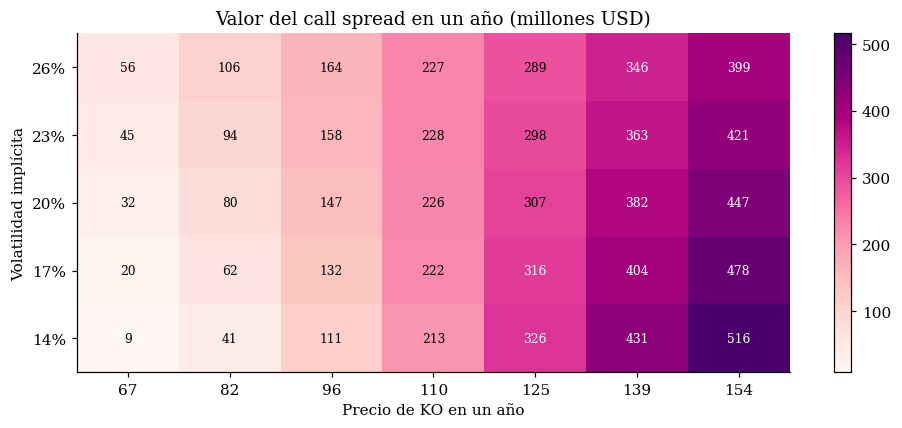

In [12]:
esc = np.array([-0.30, -0.15, 0, 0.15, 0.30, 0.60, 0.80])
valores = [(bs_call(S0 * (1 + x), K_conv, plazo - 1, rf, q, sigma) - bs_call(S0 * (1 + x), K_techo, plazo - 1, rf, q, sigma_w)) * acciones / 1e6 for x in esc]
display(pd.DataFrame({"Precio de KO": S0 * (1 + esc), "Valor call spread en 1 año (MDD)": valores,
                      "Ganancia vs. costo (MDD)": np.array(valores) - costo_neto / 1e6}, index=[f"{x:+.0%}" for x in esc]).round(1))

precios = S0 * (1 + np.array([-0.30, -0.15, 0, 0.15, 0.30, 0.45, 0.60]))
vols_h = np.array([0.14, 0.17, 0.20, 0.23, 0.26])
H = np.array([[(bs_call(s_, K_conv, plazo - 1, rf, q, v_) - bs_call(s_, K_techo, plazo - 1, rf, q, v_ - (sigma - sigma_w))) * acciones / 1e6
               for s_ in precios] for v_ in vols_h])
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(H, cmap="RdPu", aspect="auto", origin="lower")
ax.set(xticks=range(len(precios)), xticklabels=[f"{s_:.0f}" for s_ in precios], yticks=range(len(vols_h)),
       yticklabels=[f"{v_:.0%}" for v_ in vols_h], xlabel="Precio de KO en un año", ylabel="Volatilidad implícita",
       title="Valor del call spread en un año (millones USD)")
for i in range(H.shape[0]):
    for j in range(H.shape[1]): ax.text(j, i, f"{H[i, j]:.0f}", ha="center", va="center", fontsize=8,
                                        color="white" if H[i, j] > H.max() * 0.6 else "black")
ax.grid(False); plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

## 9. Monte Carlo: probabilidad de conversión y costo de la dilución
Se simulan 20,000 trayectorias de KO a cinco años con movimiento browniano geométrico neutral al riesgo.
Para cada una se calcula si el bono se convierte y cuánto le cuesta a Coca-Cola la dilución, con y sin call spread.

,Valor
Prob. de conversión (S > 120),0.3306
Prob. de superar el techo (S > 154),0.1620
VP costo de dilución sin call spread (MDD),303.0357
VP costo de dilución con call spread (MDD),145.2301
VP del call spread por Monte Carlo (MDD),157.8056
"Costo del call spread, Black-Scholes (MDD)",160.8250
"Costo al vencimiento percentil 95, sin call spread (MDD)","2,161.1496"
"Costo al vencimiento percentil 95, con call spread (MDD)","1,321.1496"


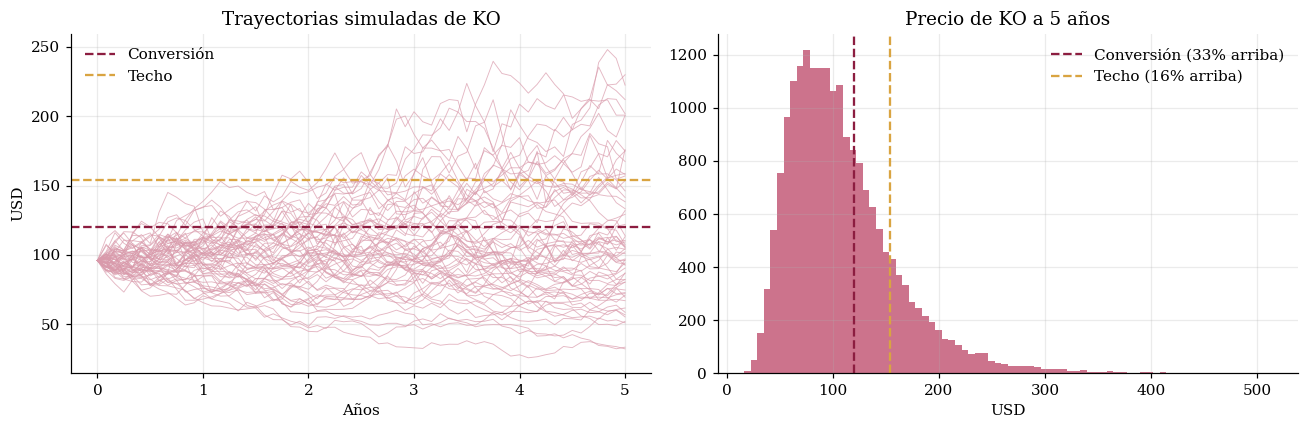

In [13]:
rng = np.random.default_rng(2026); n_sim = 20_000
Z = rng.standard_normal(n_sim)
ST_mc = S0 * np.exp((rf - q - 0.5 * sigma**2) * plazo + sigma * np.sqrt(plazo) * Z)
costo_sin = np.maximum(ST_mc - K_conv, 0) * acciones
costo_con = np.maximum(ST_mc - K_techo, 0) * acciones
desc = np.exp(-rf * plazo)
mc = pd.DataFrame({"Valor": [np.mean(ST_mc > K_conv), np.mean(ST_mc > K_techo), desc * costo_sin.mean() / 1e6,
                             desc * costo_con.mean() / 1e6, desc * (costo_sin - costo_con).mean() / 1e6, costo_neto / 1e6,
                             np.percentile(costo_sin, 95) / 1e6, np.percentile(costo_con, 95) / 1e6]},
                  index=["Prob. de conversión (S > 120)", "Prob. de superar el techo (S > 154)",
                         "VP costo de dilución sin call spread (MDD)", "VP costo de dilución con call spread (MDD)",
                         "VP del call spread por Monte Carlo (MDD)", "Costo del call spread, Black-Scholes (MDD)",
                         "Costo al vencimiento percentil 95, sin call spread (MDD)", "Costo al vencimiento percentil 95, con call spread (MDD)"])
display(mc)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
idx = rng.choice(n_sim, 60, replace=False); t_ = np.linspace(0, plazo, 61)
W = np.cumsum(rng.standard_normal((60, 60)) * np.sqrt(plazo / 60), axis=1)
tray = S0 * np.exp((rf - q - 0.5 * sigma**2) * t_[1:] + sigma * W)
for row in tray: ax[0].plot(t_, np.r_[S0, row], color=BERRY[2], lw=0.6, alpha=0.7)
ax[0].axhline(K_conv, color=BERRY[0], ls="--", label="Conversión"); ax[0].axhline(K_techo, color=BERRY[3], ls="--", label="Techo")
ax[0].set(title="Trayectorias simuladas de KO", xlabel="Años", ylabel="USD"); ax[0].legend(frameon=False)
ax[1].hist(ST_mc, bins=80, color=BERRY[1], alpha=0.8)
ax[1].axvline(K_conv, color=BERRY[0], ls="--", label=f"Conversión ({np.mean(ST_mc > K_conv):.0%} arriba)")
ax[1].axvline(K_techo, color=BERRY[3], ls="--", label=f"Techo ({np.mean(ST_mc > K_techo):.0%} arriba)")
ax[1].set(title="Precio de KO a 5 años", xlabel="USD"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

**Lectura.** El Monte Carlo da un valor del call spread muy cercano al de Black-Scholes; la pequeña diferencia viene
de que la simulación usa una sola volatilidad para las dos piernas. Además muestra lo que compra Coca-Cola:
en el 5 % de los peores escenarios para la empresa, el costo de la dilución baja de forma importante con el call
spread. Este es el argumento central del caso Molson Coors: se paga una prima hoy para limitar la dilución futura.

## 10. Cobertura de tasa: T-lock con el DV01 de Bloomberg
Bloomberg SWPM da un DV01 de 4,456 dólares por cada 10 millones de nocional en un swap a 5 años, equivalente a una
duración modificada de 4.46 años.

In [14]:
dv01_10mm = 4456.30
dv01 = dv01_10mm * monto / 10e6
cambios = np.array([-50, -25, 0, 25, 50, 100])
tl = pd.DataFrame({"Tesoro resultante (%)": (rf * 1e4 + cambios) / 100,
                   "Pago del T-lock (MDD)": dv01 * cambios / 1e6,
                   "Mayor costo de la emisión (MDD)": dv01 * cambios / 1e6,
                   "Resultado neto (MDD)": dv01 * cambios / 1e6 - dv01 * cambios / 1e6}, index=[f"{c:+d} pb" for c in cambios])
print(f"DV01 de la emisión: {dv01 / 1e6:.2f} millones de USD por punto base")
print(f"Diferencial swap - Tesoro: {(swap5 - rf) * 1e4:.1f} pb")
tl.round({"Tesoro resultante (%)": 2, "Pago del T-lock (MDD)": 1, "Mayor costo de la emisión (MDD)": 1, "Resultado neto (MDD)": 1})

DV01 de la emisión: 1.34 millones de USD por punto base
Diferencial swap - Tesoro: -27.9 pb


,Tesoro resultante (%),Pago del T-lock (MDD),Mayor costo de la emisión (MDD),Resultado neto (MDD)
-50 pb,4.1800,-66.8000,-66.8000,0.0000
-25 pb,4.4300,-33.4000,-33.4000,0.0000
+0 pb,4.6800,0.0000,0.0000,0.0000
+25 pb,4.9300,33.4000,33.4000,0.0000
+50 pb,5.1800,66.8000,66.8000,0.0000
+100 pb,5.6800,133.7000,133.7000,0.0000


**Lectura.** El Tesoro a 5 años se movió de 3.50 % a 5.09 % en el último año (Bloomberg USGG5YR). Con un DV01 de
1.34 millones por punto base, un alza de 25 pb durante la colocación costaría unos 33 millones; el T-lock la compensa.
El swap SOFR está 28 pb por debajo del Tesoro, así que fijar la tasa con un swap de inicio diferido sería un poco más barato.

## 11. Resultado del portafolio de cobertura en Investopedia (6 al 9 de noviembre)

,Posición,Riesgo,Cantidad,Multiplicador,Entrada,Salida,P&L,Rend. %
0,KO acciones,Acción,1000,1,95.9900,95.8300,-160.0000,-0.1700
1,KO Put 95,Acción,10,100,2.3300,2.1500,-180.0000,-7.7300
2,FXE Put 103,Tipo de cambio,10,100,1.0500,0.4500,-600.0000,-57.1400
3,TLT Put 82,Tasa,10,100,1.5200,1.4200,-100.0000,-6.5800
4,USO Call 149,Energía,10,100,11.4500,7.9500,"-3,500.0000",-30.5700


P&L total de la cobertura: -4,540 USD


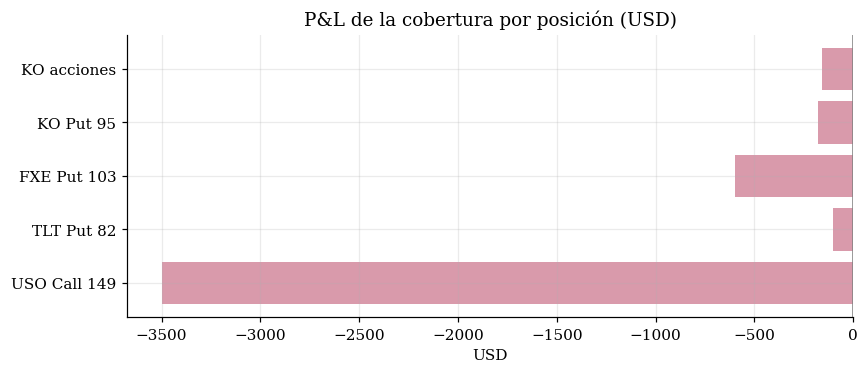

In [15]:
ops = pd.DataFrame({
    "Posición": ["KO acciones", "KO Put 95", "FXE Put 103", "TLT Put 82", "USO Call 149"],
    "Riesgo": ["Acción", "Acción", "Tipo de cambio", "Tasa", "Energía"],
    "Cantidad": [1000, 10, 10, 10, 10], "Multiplicador": [1, 100, 100, 100, 100],
    "Entrada": [95.99, 2.33, 1.05, 1.52, 11.45], "Salida": [95.83, 2.15, 0.45, 1.42, 7.95]})
ops["P&L"] = (ops["Salida"] - ops["Entrada"]) * ops["Cantidad"] * ops["Multiplicador"]
ops["Rend. %"] = (ops["Salida"] / ops["Entrada"] - 1) * 100
display(ops.round(2))
print(f"P&L total de la cobertura: {ops['P&L'].sum():,.0f} USD")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(ops["Posición"][::-1], ops["P&L"][::-1], color=BERRY[2]); ax.axvline(0, color="gray", lw=1)
ax.set(title="P&L de la cobertura por posición (USD)", xlabel="USD"); plt.tight_layout(); plt.show()

## 12. Conclusión
Con los datos de Bloomberg del 9 de noviembre de 2026, el convertible permite a Coca-Cola pagar un cupón justo cercano
a 2.7 % en lugar de 5.0 % de la deuda recta, un ahorro de unos 69 millones de dólares al año sobre 3,000 millones. El
call spread que eleva la prima efectiva de 25 % a 60 % cuesta alrededor de 161 millones (5.4 % de la emisión), se paga
con unos 2.3 años de ahorro y, según el Monte Carlo, reduce de forma importante el costo de la dilución en los peores
escenarios. Recomendamos el convertible con call spread y T-lock.

El portafolio de cobertura del simulador perdió 4,540 dólares porque ningún riesgo se materializó en tres días: las
opciones compradas perdieron su prima. Una tesorería real usaría instrumentos sin prima (forwards, futuros, collars y
swaps), dimensionados contra la exposición y sostenidos durante todo el horizonte del riesgo.